# 신경망 모델 훈련

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"  # torch import 전에 설정

import copy

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets

from lightning.pytorch.callbacks import ModelCheckpoint, EarlyStopping

W1121 11:12:02.549000 19148 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


## seed / determinism

In [2]:
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.benchmark = False

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


In [4]:
criterion = nn.CrossEntropyLoss()

## data

In [5]:
tr = datasets.FashionMNIST(root='./data', train=True, download=True)
te = datasets.FashionMNIST(root='./data', train=False, download=True)
train_input, train_target = tr.data.numpy(), tr.targets.numpy()
test_input, test_target = te.data.numpy(), te.targets.numpy()
train_scaled, test_scaled = train_input/255.0, test_input/255.0
train_scaled, val_scaled, train_target, val_target = train_test_split(
    train_scaled, train_target, test_size=0.2, random_state=42
)
print(train_scaled.shape, train_target.shape)
print(val_scaled.shape, val_target.shape)
print(test_scaled.shape, test_target.shape)

(48000, 28, 28) (48000,)
(12000, 28, 28) (12000,)
(10000, 28, 28) (10000,)


In [6]:
X_train = torch.tensor(train_scaled, dtype=torch.float32)
y_train = torch.tensor(train_target, dtype=torch.long)
X_val = torch.tensor(val_scaled, dtype=torch.float32)
y_val = torch.tensor(val_target, dtype=torch.long)
print(X_train.shape, y_train.shape, X_val.shape, y_val.shape)

torch.Size([48000, 28, 28]) torch.Size([48000]) torch.Size([12000, 28, 28]) torch.Size([12000])


In [7]:
g = torch.Generator().manual_seed(SEED)
train_ds = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, generator=g)

val_ds = TensorDataset(X_val, y_val)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False)   # shuffle=False 는 generator 불필요

## model

In [8]:
def model_fn(a_layer=None):
    layers = [nn.Flatten(), nn.Linear(784, 100), nn.ReLU()]
    if a_layer is not None:
        layers.append(a_layer)
    layers.append(nn.Linear(100, 10))   # softmax는 CrossEntropyLoss에 포함
    model = nn.Sequential(*layers)
    return model.to(device)

def summary(model):
    print(model)
    print("params:", sum(p.numel() for p in model.parameters()))

## train / eval

In [9]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = criterion(out, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            n += xb.size(0)
    return total_loss / n, correct / n


def evaluate(model, loader=val_loader):
    loss, acc = run_epoch(model, loader)
    print(f"val loss: {loss:.4f} - val accuracy: {acc:.4f}")
    return loss, acc


def fit(model, train_loader, optimizer, epochs=5, validation=False, callbacks=None):
    """Keras fit() 대응. history dict 반환. callbacks는 on_epoch_end(epoch, model, logs)를 가진 객체."""
    history = {"loss": [], "accuracy": []}
    if validation:
        history.update({"val_loss": [], "val_accuracy": []})
    callbacks = callbacks or []
    # train_loader = make_train_loader()

    for epoch in range(epochs):
        loss, acc = run_epoch(model, train_loader, optimizer)
        history["loss"].append(loss)
        history["accuracy"].append(acc)
        logs = {"loss": loss, "accuracy": acc}
        if validation:
            v_loss, v_acc = run_epoch(model, val_loader)
            history["val_loss"].append(v_loss)
            history["val_accuracy"].append(v_acc)
            logs.update({"val_loss": v_loss, "val_accuracy": v_acc})

        stop = False
        for cb in callbacks:
            if cb.on_epoch_end(epoch, model, logs):
                stop = True
        if stop:
            break

    for cb in callbacks:
        if hasattr(cb, "on_train_end"):
            cb.on_train_end(model)
    return history

## callbacks (Keras ModelCheckpoint / EarlyStopping 대응)

In [ ]:
# from lightning.pytorch.callbacks import ModelCheckpoint, EarlyStopping

```python
class ModelCheckpoint:
    def __init__(self, path, save_best_only=True):
        self.path, self.best = path, float("inf")
        self.save_best_only = save_best_only

    def on_epoch_end(self, epoch, model, logs):
        if not self.save_best_only or logs["val_loss"] < self.best:
            self.best = logs["val_loss"]
            torch.save(model.state_dict(), self.path)
        return False


class EarlyStopping:
    def __init__(self, patience=2, restore_best_weights=True):
        self.patience, self.restore = patience, restore_best_weights
        self.best, self.wait, self.best_state = float("inf"), 0, None
        self.stopped_epoch = 0

    def on_epoch_end(self, epoch, model, logs):
        if logs["val_loss"] < self.best:
            self.best, self.wait = logs["val_loss"], 0
            self.best_state = copy.deepcopy(model.state_dict())
            return False
        self.wait += 1
        if self.wait >= self.patience:
            self.stopped_epoch = epoch
            return True
        return False

    def on_train_end(self, model):
        if self.restore and self.best_state is not None:
            model.load_state_dict(self.best_state)
    ```

## 1) 기본 모델, 5 epoch

In [11]:
model = model_fn()
summary(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=100, bias=True)
  (2): ReLU()
  (3): Linear(in_features=100, out_features=10, bias=True)
)
params: 79510


In [12]:
sgd = torch.optim.SGD(params=model.parameters(), lr=0.001, momentum=0.0, nesterov=False)
rmsprop = torch.optim.RMSprop(params=model.parameters(), lr=0.01, alpha=0.99, eps=1e-8, momentum=0.0)
adagrad = torch.optim.Adagrad(params=model.parameters(), lr=0.01, initial_accumulator_value=0.0, eps=1e-10)
adam = torch.optim.Adam(params=model.parameters(), lr=0.001, betas=(0.9, 0.999), eps=1e-8)

In [13]:
history = fit(model, train_loader=train_loader, optimizer=sgd, epochs=5)  # validation=False, callbacks=None
print(history.keys())

dict_keys(['loss', 'accuracy'])


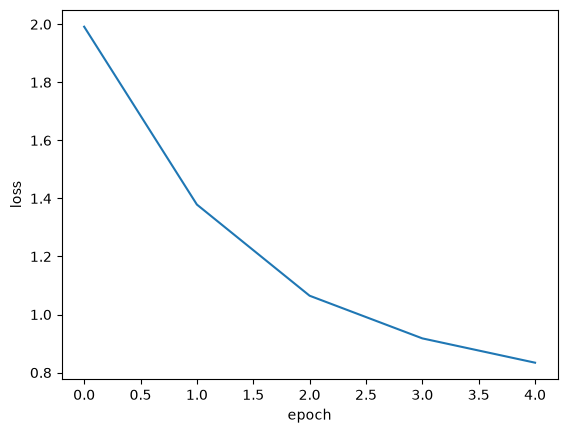

In [14]:
plt.plot(history['loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

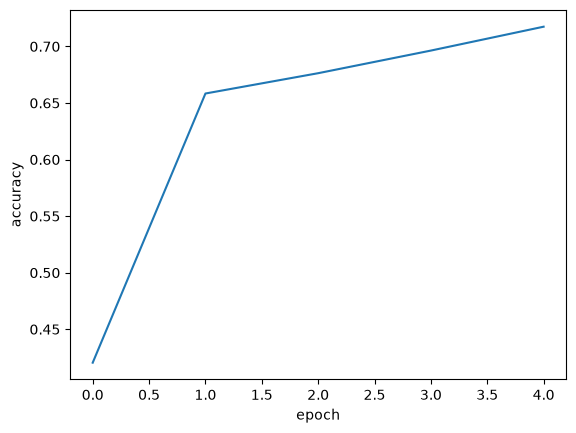

In [15]:
plt.plot(history['accuracy'])
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.show()

## 2) 20 epoch

In [16]:
model = model_fn()
summary(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=100, bias=True)
  (2): ReLU()
  (3): Linear(in_features=100, out_features=10, bias=True)
)
params: 79510


In [17]:
sgd = torch.optim.SGD(params=model.parameters(), lr=0.001, momentum=0.0, nesterov=False)
rmsprop = torch.optim.RMSprop(params=model.parameters(), lr=0.01, alpha=0.99, eps=1e-8, momentum=0.0)
adagrad = torch.optim.Adagrad(params=model.parameters(), lr=0.01, initial_accumulator_value=0.0, eps=1e-10)
adam = torch.optim.Adam(params=model.parameters(), lr=0.001, betas=(0.9, 0.999), eps=1e-8)

In [18]:
history = fit(model, train_loader=train_loader, optimizer=rmsprop, epochs=20)  # validation=False, callbacks=None
print(history.keys())

KeyboardInterrupt: 

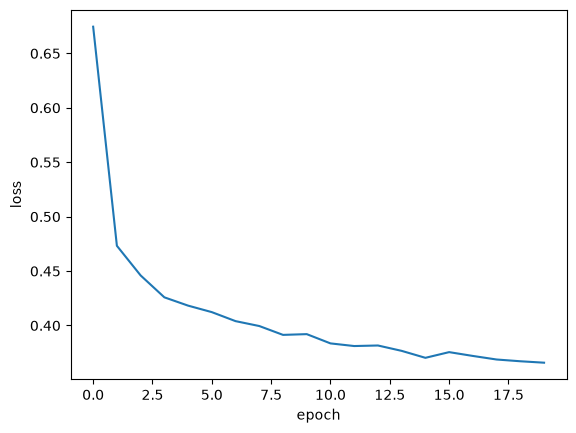

In [ ]:
plt.plot(history['loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

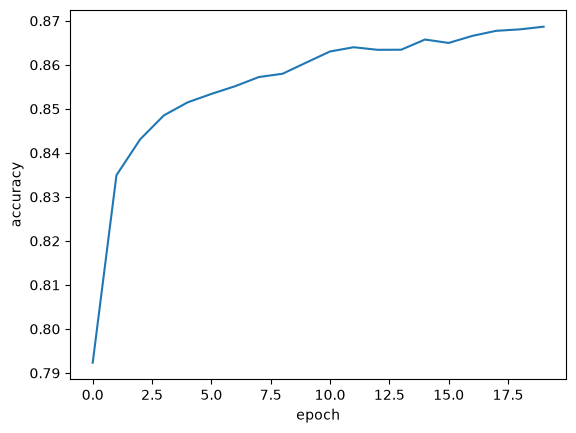

In [ ]:
plt.plot(history['accuracy'])
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.show()

## 3) 검증 손실 함께 확인

In [ ]:
model = model_fn()
summary(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=100, bias=True)
  (2): ReLU()
  (3): Linear(in_features=100, out_features=10, bias=True)
)
params: 79510


In [ ]:
sgd = torch.optim.SGD(params=model.parameters(), lr=0.001, momentum=0.0, nesterov=False)
rmsprop = torch.optim.RMSprop(params=model.parameters(), lr=0.01, alpha=0.99, eps=1e-8, momentum=0.0)
adagrad = torch.optim.Adagrad(params=model.parameters(), lr=0.01, initial_accumulator_value=0.0, eps=1e-10)
adam = torch.optim.Adam(params=model.parameters(), lr=0.001, betas=(0.9, 0.999), eps=1e-8)

In [ ]:
history = fit(model, train_loader=train_loader, optimizer=adagrad, epochs=20, validation=True)  # callbacks=None
print(history.keys())

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


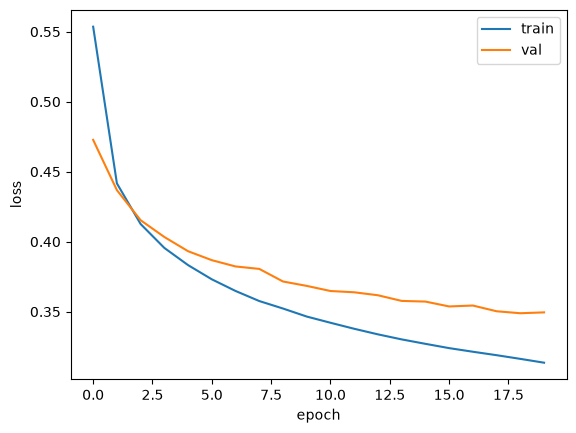

In [ ]:
plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

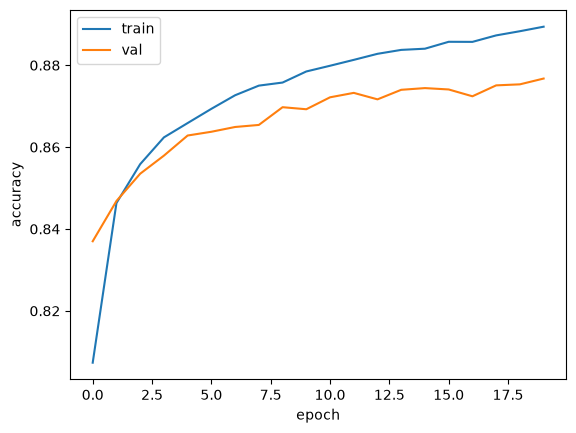

In [ ]:
plt.plot(history['accuracy'])
plt.plot(history['val_accuracy'])
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend(['train', 'val'])
plt.show()

## 4) Adam

In [ ]:
model = model_fn()
summary(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=100, bias=True)
  (2): ReLU()
  (3): Linear(in_features=100, out_features=10, bias=True)
)
params: 79510


In [ ]:
sgd = torch.optim.SGD(params=model.parameters(), lr=0.001, momentum=0.0, nesterov=False)
rmsprop = torch.optim.RMSprop(params=model.parameters(), lr=0.01, alpha=0.99, eps=1e-8, momentum=0.0)
adagrad = torch.optim.Adagrad(params=model.parameters(), lr=0.01, initial_accumulator_value=0.0, eps=1e-10)
adam = torch.optim.Adam(params=model.parameters(), lr=0.001, betas=(0.9, 0.999), eps=1e-8)

In [ ]:
history = fit(model, train_loader=train_loader, optimizer=adam, epochs=20, validation=True)  # callbacks=None
print(history.keys())

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


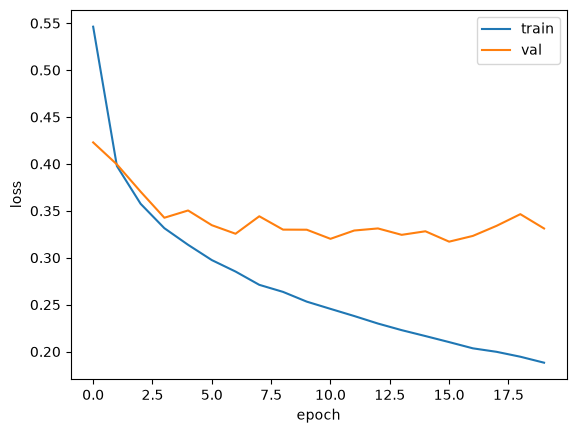

In [ ]:
plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

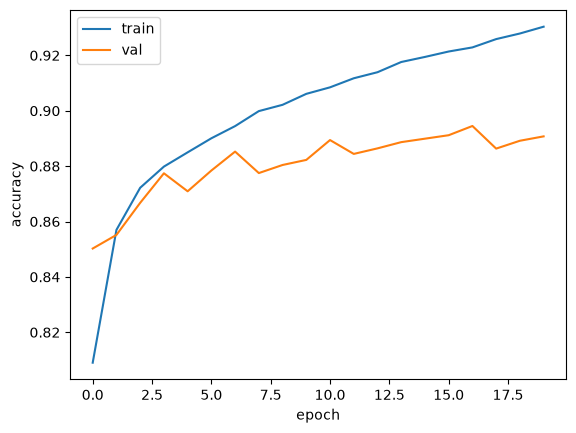

In [ ]:
plt.plot(history['accuracy'])
plt.plot(history['val_accuracy'])
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend(['train', 'val'])
plt.show()

## 5) Dropout(0.3)

In [ ]:
model = model_fn(nn.Dropout(0.3))
summary(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=100, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=100, out_features=10, bias=True)
)
params: 79510


In [ ]:
sgd = torch.optim.SGD(params=model.parameters(), lr=0.001, momentum=0.0, nesterov=False)
rmsprop = torch.optim.RMSprop(params=model.parameters(), lr=0.01, alpha=0.99, eps=1e-8, momentum=0.0)
adagrad = torch.optim.Adagrad(params=model.parameters(), lr=0.01, initial_accumulator_value=0.0, eps=1e-10)
adam = torch.optim.Adam(params=model.parameters(), lr=0.001, betas=(0.9, 0.999), eps=1e-8)

In [ ]:
history = fit(model, train_loader=train_loader, optimizer=adam, epochs=20, validation=True)  # callbacks=None
print(history.keys())

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


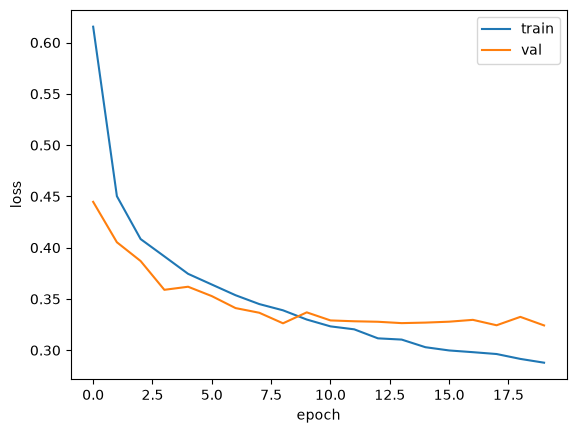

In [ ]:
plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

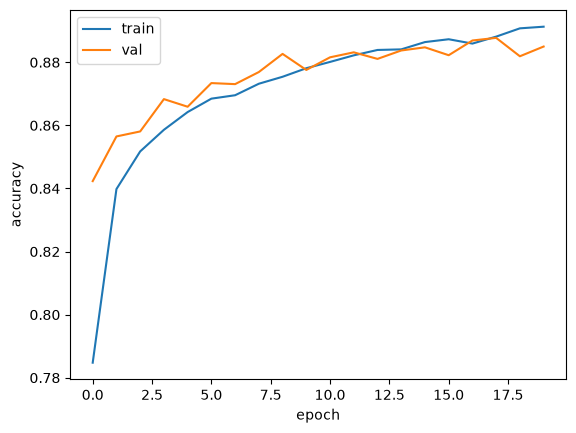

In [ ]:
plt.plot(history['accuracy'])
plt.plot(history['val_accuracy'])
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend(['train', 'val'])
plt.show()

## 6) 모델 저장 / 불러오기

In [ ]:
model = model_fn(nn.Dropout(0.3))
summary(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=100, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=100, out_features=10, bias=True)
)
params: 79510


In [ ]:
sgd = torch.optim.SGD(params=model.parameters(), lr=0.001, momentum=0.0, nesterov=False)
rmsprop = torch.optim.RMSprop(params=model.parameters(), lr=0.01, alpha=0.99, eps=1e-8, momentum=0.0)
adagrad = torch.optim.Adagrad(params=model.parameters(), lr=0.01, initial_accumulator_value=0.0, eps=1e-10)
adam = torch.optim.Adam(params=model.parameters(), lr=0.001, betas=(0.9, 0.999), eps=1e-8)

In [ ]:
history = fit(model, train_loader=train_loader, optimizer=adam, epochs=10, validation=True)  # callbacks=None
print(history.keys())

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])


In [ ]:
model_whole_path = './model-whole.pt'       # 모델 전체 (model.save 대응)
model_weights_path = './model.weights.pt'   # 가중치만 (save_weights 대응)

if not os.path.exists(model_whole_path):
    torch.save(model, model_whole_path)

if not os.path.exists(model_weights_path):
    torch.save(model.state_dict(), model_weights_path)

가중치 불러오기

In [ ]:
model = model_fn(nn.Dropout(0.3))
model_weights_path = './model.weights.pt'   # 가중치만 (save_weights 대응)
model.load_state_dict(torch.load(model_weights_path, map_location=device, weights_only=True))
model.eval()

with torch.no_grad():
    val_labels = model(X_val.to(device)).argmax(1).cpu().numpy()
print(np.mean(val_labels == val_target))

0.8810833333333333


모델 전체 불러오기 (PyTorch 2.6+는 weights_only=False 필요)

In [ ]:
model_whole_path = './model-whole.pt'       # 모델 전체 (model.save 대응)
model = torch.load(model_whole_path, map_location=device, weights_only=False)
evaluate(model)

val loss: 0.3300 - val accuracy: 0.8811


(0.330045124232769, 0.8810833333333333)

## 7) ModelCheckpoint

In [ ]:
model = model_fn(nn.Dropout(0.3))
summary(model)

In [ ]:
sgd = torch.optim.SGD(params=model.parameters(), lr=0.001, momentum=0.0, nesterov=False)
rmsprop = torch.optim.RMSprop(params=model.parameters(), lr=0.01, alpha=0.99, eps=1e-8, momentum=0.0)
adagrad = torch.optim.Adagrad(params=model.parameters(), lr=0.01, initial_accumulator_value=0.0, eps=1e-10)
adam = torch.optim.Adam(params=model.parameters(), lr=0.001, betas=(0.9, 0.999), eps=1e-8)

In [ ]:
best_model_path = './best-model.pt'
checkpoint_db = ModelCheckpoint(best_model_path, save_best_only=True)
history = fit(model, train_loader=train_loader, optimizer=adam, epochs=20, validation=True, callbacks=[checkpoint_db])

In [ ]:
model = model_fn(nn.Dropout(0.3))
best_model_path = './best-model.pt'
model.load_state_dict(torch.load(best_model_path, map_location=device, weights_only=False))
evaluate(model)

val loss: 0.3201 - val accuracy: 0.8851


(0.3200758991042773, 0.8850833333333333)

## 8) ModelCheckpoint + EarlyStopping

In [ ]:
model = model_fn(nn.Dropout(0.3))
summary(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=100, bias=True)
  (2): ReLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=100, out_features=10, bias=True)
)
params: 79510


In [ ]:
sgd = torch.optim.SGD(params=model.parameters(), lr=0.001, momentum=0.0, nesterov=False)
rmsprop = torch.optim.RMSprop(params=model.parameters(), lr=0.01, alpha=0.99, eps=1e-8, momentum=0.0)
adagrad = torch.optim.Adagrad(params=model.parameters(), lr=0.01, initial_accumulator_value=0.0, eps=1e-10)
adam = torch.optim.Adam(params=model.parameters(), lr=0.001, betas=(0.9, 0.999), eps=1e-8)

In [ ]:
best_model_path = './best-model.pt'
checkpoint_db = ModelCheckpoint(best_model_path, save_best_only=True)
early_stopping_cb = EarlyStopping(patience=2, restore_best_weights=True)
history = fit(model, train_loader=train_loader, optimizer=adam, epochs=20, validation=True, callbacks=[checkpoint_db, early_stopping_cb])
print(early_stopping_cb.stopped_epoch)

11


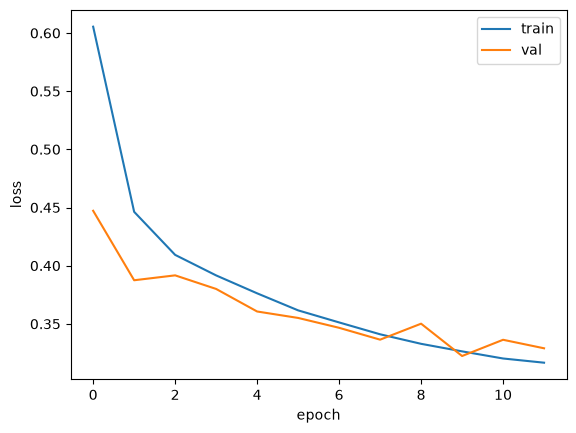

In [ ]:
plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend(['train', 'val'])
plt.show()

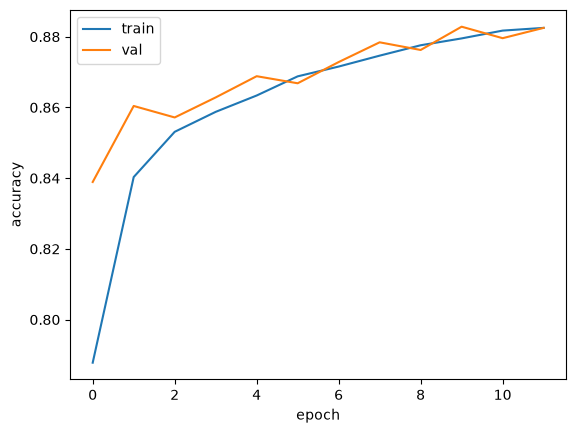

In [ ]:
plt.plot(history['accuracy'])
plt.plot(history['val_accuracy'])
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.legend(['train', 'val'])
plt.show()

In [ ]:
evaluate(model)

val loss: 0.3224 - val accuracy: 0.8828


(0.32236261826753615, 0.8828333333333334)